# Prediction housing prices

## Описание задачи

### Введение

Прогнозирование стоимости жилой недвижимости — одна из классических задач регрессии в машинном обучении, имеющая прямую практическую ценность для участников рынка: банков (ипотечный скоринг), застройщиков, риелторов и покупателей. Точная оценка цены позволяет принимать обоснованные решения: определять справедливую стоимость объекта, формировать резервы, оценивать риски и оптимизировать стратегии продаж.

В качестве источника данных используется датасет Ames Housing, собранный Дином Де Коком как современная и расширенная альтернатива набору Boston Housing. Датасет содержит сведения о жилых домах в Эймсе (штат Айова) и включает 79 объясняющих переменных, охватывающих широкий спектр характеристик: площадь, год постройки, качество отделки, наличие улучшений (бассейн, гараж), локационные и инфраструктурные факторы. Такой набор признаков позволяет моделировать нелинейные зависимости и взаимодействия, характерные для ценообразования на рынке жилья.

Особенностью задачи является специфика метрики оценки: решения ранжируются по RMSE между логарифмами предсказанных и фактических цен. Такой подход нивелирует влияние масштаба и делает ошибки на дорогих и дешёвых объектах сопоставимыми по значимости, что соответствует экономическим реалиям рынка.

Учитывая сложность структуры данных (большое количество категориальных признаков, семантические пропуски, потенциальные выбросы), для решения задачи целесообразно применять ансамблевые методы градиентного бустинга (CatBoost, XGBoost, LightGBM), которые хорошо справляются с разнородными признаками и нелинейностями. Инженерный пайплайн должен включать продуманную предобработку, генерацию признаков, кросс‑валидацию и оптимизацию гиперпараметров, что согласуется с лучшими практиками в области кредитного и скорингового моделирования.

### Цель проекта

Построить и валидировать модель машинного обучения для прогнозирования цены продажи жилого дома на основе 79 характеристик объекта в городе Эймс, штат Айова, обеспечив минимальное значение метрики RMSE при соблюдении требований к стабильности, интерпретируемости и воспроизводимости результатов.

### Задачи

- Подготовка и первичный анализ данных: загрузка датасета, проверка целостности, выявление дубликатов, анализ типов признаков и распределения целевой переменной; визуализация исходного распределения SalePrice и обоснование логарифмического преобразования.

- Предобработка признаков: заполнение пропусков с учётом семантики (например, «отсутствие признака» как отдельная категория), кодирование категориальных переменных, обработка выбросов и приведение данных к формату, пригодному для обучения моделей.

- Генерация признаков (feature engineering): создание новых переменных, отражающих экономические и строительные закономерности (возраст дома, общая жилая площадь, соотношение площадей, индикаторы наличия улучшений, взаимодействия ключевых факторов качества и площади).

- Формирование валидационной стратегии: выбор схемы кросс‑валидации (KFold) с учётом специфики задачи (отсутствие временной зависимости), обеспечение репрезентативности фолдов по распределению логарифма цены.

- Обучение и подбор моделей: реализация пайплайна с моделями градиентного бустинга (в первую очередь CatBoost как наиболее подходящего для смешанных признаков), подбор гиперпараметров с помощью Optuna, сравнение альтернативных алгоритмов (XGBoost, LightGBM) при необходимости.

- Оценка качества и стабильности: расчёт RMSE на валидационных фолдах, анализ разброса метрик, построение кривых обучения, проверка устойчивости предсказаний к изменениям в данных.

- Интерпретация результатов: анализ важности признаков (feature importance), выявление ключевых драйверов цены, сопоставление с рыночными ожиданиями и здравым смыслом.

- Финализация и вывод результатов: обучение итоговой модели на полном обучающем наборе, генерация предсказаний для тестовой выборки, обратное преобразование логарифмических оценок в абсолютные цены, формирование файла для отправки на платформу соревнования.

- Документирование и воспроизводимость: описание шагов предобработки, параметров модели и логики принятия решений, обеспечение возможности повторного запуска пайплайна и воспроизведения результатов.

## Данные

### Описания файлов

- train.csv - обучающий набор
- test.csv - тестовый набор
- data_description.txt - полное описание каждой колонки, первоначально подготовленное Дином Де Коком, но слегка отредактированное, чтобы соответствовать названиям колонок, используемым здесь
- sample_submission.csv - эталонная отправка на основе линейной регрессии по году и месяцу продажи, метражу участка и количеству спален

### Данные таблицы

- SalePrice - the property's sale price in dollars. This is the target variable that you're trying to predict.
- MSSubClass: The building class
- MSZoning: The general zoning classification
- LotFrontage: Linear feet of street connected to property
- LotArea: Lot size in square feet
- Street: Type of road access
- Alley: Type of alley access
- LotShape: General shape of property
- LandContour: Flatness of the property
- Utilities: Type of utilities available
- LotConfig: Lot configuration
- LandSlope: Slope of property
- Neighborhood: Physical locations within Ames city limits
- Condition1: Proximity to main road or railroad
- Condition2: Proximity to main road or railroad (if a second is present)
- BldgType: Type of dwelling
- HouseStyle: Style of dwelling
- OverallQual: Overall material and finish quality
- OverallCond: Overall condition rating
- YearBuilt: Original construction date
- YearRemodAdd: Remodel date
- RoofStyle: Type of roof
- RoofMatl: Roof material
- Exterior1st: Exterior covering on house
- Exterior2nd: Exterior covering on house (if more than one material)
- MasVnrType: Masonry veneer type
- MasVnrArea: Masonry veneer area in square feet
- ExterQual: Exterior material quality
- ExterCond: Present condition of the material on the exterior
- Foundation: Type of foundation
- BsmtQual: Height of the basement
- BsmtCond: General condition of the basement
- BsmtExposure: Walkout or garden level basement walls
- BsmtFinType1: Quality of basement finished area
- BsmtFinSF1: Type 1 finished square feet
- BsmtFinType2: Quality of second finished area (if present)
- BsmtFinSF2: Type 2 finished square feet
- BsmtUnfSF: Unfinished square feet of basement area
- TotalBsmtSF: Total square feet of basement area
- Heating: Type of heating
- HeatingQC: Heating quality and condition
- CentralAir: Central air conditioning
- Electrical: Electrical system
- 1stFlrSF: First Floor square feet
- 2ndFlrSF: Second floor square feet
- LowQualFinSF: Low quality finished square feet (all floors)
- GrLivArea: Above grade (ground) living area square feet
- BsmtFullBath: Basement full bathrooms
- BsmtHalfBath: Basement half bathrooms
- FullBath: Full bathrooms above grade
- HalfBath: Half baths above grade
- Bedroom: Number of bedrooms above basement level
- Kitchen: Number of kitchens
- KitchenQual: Kitchen quality
- TotRmsAbvGrd: Total rooms above grade (does not include bathrooms)
- Functional: Home functionality rating
- Fireplaces: Number of fireplaces
- FireplaceQu: Fireplace quality
- GarageType: Garage location
- GarageYrBlt: Year garage was built
- GarageFinish: Interior finish of the garage
- GarageCars: Size of garage in car capacity
- GarageArea: Size of garage in square feet
- GarageQual: Garage quality
- GarageCond: Garage condition
- PavedDrive: Paved driveway
- WoodDeckSF: Wood deck area in square feet
- OpenPorchSF: Open porch area in square feet
- EnclosedPorch: Enclosed porch area in square feet
- 3SsnPorch: Three season porch area in square feet
- ScreenPorch: Screen porch area in square feet
- PoolArea: Pool area in square feet
- PoolQC: Pool quality
- Fence: Fence quality
- MiscFeature: Miscellaneous feature not covered in other categories
- MiscVal: $Value of miscellaneous feature
- MoSold: Month Sold
- YrSold: Year Sold
- SaleType: Type of sale
- SaleCondition: Condition of sale

## Загрузка модулей

### Установка модулей

In [1]:
!pip install phik -q
!pip install optuna -q
!pip install shap -q

### Импорт библиотек

In [2]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import time
import optuna
import shap
from phik import phik_matrix
from datetime import date
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer
from catboost import CatBoostRegressor, Pool

In [3]:
from IPython.display import display, Markdown

## Разведочный анализ данных

### Загрузка и изучение данных

In [4]:
# Загрузка датасетов
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

In [5]:
display(train_df.head())
display(test_df.head())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [6]:
train_df.info()
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

**Общий объём и структура**

- Train: 1460 объектов, 81 колонка (включая SalePrice).
- Test: 1459 объектов, 80 колонок (без SalePrice, как и положено).

Типы признаков и баланс
- Числовые: 35 в train, 26 в test (разница из‑за приведения типов при чтении).
- Категориальные (object): 43 в обоих.

Float: в train их мало (3), в test — много (11): это следствие того, что некоторые целочисленные колонки (например, площади подвалов, количество ванных) в test стали float из‑за пропусков. Это типично и не ошибка — просто pandas так обрабатывает NaN.
Практический вывод: при построении пайплайна нужно явно приводить типы (например, BsmtFinSF1, GarageCars обратно в int, если нет NaN, либо оставить float и корректно обрабатывать пропуски). Для CatBoost это менее критично, для XGBoost/LightGBM — важно.


### Анализ пропущенных значений

In [7]:
def analyze_na_strategies(df, name='train'):
   
    na_counts = df.isna().sum()
    na_pct = (na_counts / len(df) * 100).round(2)
    
    # Ключевые группы колонок по семантике (под Ames Housing)
    semantic_cat_none = [
        'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
        'GarageQual', 'GarageCond', 'GarageFinish', 'GarageType',
        'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
        'MasVnrType'
    ]
    
    semantic_num_zero = ['MasVnrArea', 'GarageYrBlt']
    real_missing_median = ['LotFrontage']
    rare_missing_mode = ['Electrical', 'MSZoning', 'Utilities']
    
    def get_strategy(col):
        if col in semantic_cat_none:
            return 'Fill "None" (semantic: feature absent)'
        elif col in semantic_num_zero:
            return 'Fill 0 (semantic: feature absent)'
        elif col in real_missing_median:
            return 'Median by Neighborhood (real missing data)'
        elif col in rare_missing_mode:
            return 'Mode by Neighborhood (rare missing)'
        else:
            return 'Inspect further / custom strategy'
    
    strategies = na_counts.index.map(get_strategy)
    
    result = pd.DataFrame({
        'count': na_counts,
        'pct': na_pct,
        'strategy': strategies
    })
    
    # Оставляем только колонки с пропусками и сортируем по убыванию
    result = result[result['count'] > 0].sort_values(by='count', ascending=False)
    return result

# Применение к train и test
train_na_analysis = analyze_na_strategies(train_df, name='train')
test_na_analysis = analyze_na_strategies(test_df, name='test')

# Быстрый вывод
print("=== Train NAN Analysis ===")
print(train_na_analysis)
print("\n=== Test NAN Analysis ===")
print(test_na_analysis)

=== Train NAN Analysis ===
              count    pct                                    strategy
PoolQC         1453  99.52      Fill "None" (semantic: feature absent)
MiscFeature    1406  96.30      Fill "None" (semantic: feature absent)
Alley          1369  93.77      Fill "None" (semantic: feature absent)
Fence          1179  80.75      Fill "None" (semantic: feature absent)
MasVnrType      872  59.73      Fill "None" (semantic: feature absent)
FireplaceQu     690  47.26      Fill "None" (semantic: feature absent)
LotFrontage     259  17.74  Median by Neighborhood (real missing data)
GarageType       81   5.55      Fill "None" (semantic: feature absent)
GarageYrBlt      81   5.55           Fill 0 (semantic: feature absent)
GarageFinish     81   5.55      Fill "None" (semantic: feature absent)
GarageQual       81   5.55      Fill "None" (semantic: feature absent)
GarageCond       81   5.55      Fill "None" (semantic: feature absent)
BsmtFinType2     38   2.60      Fill "None" (seman

Пропуски и их семантика 
В датасете много колонок с большим числом пропусков, и во многих случаях это не случайные пропуски, а отсутствие признака:

- Alley: 91 непустых в train (очень мало) → почти у всех домов нет аллеи. Заполнять «None» — правильная стратегия.
- PoolQC: всего 7 непустых → почти у всех нет бассейна. «None» здесь — семантически верный класс.
- Fence, MiscFeature: очень мало непустых значений → признак редкий, лучше кодировать «None».
- LotFrontage: ~25% пропусков → это реальный пропуск, здесь лучше заполнять медианой по району или медианным значением.
- MasVnrType/Area, BsmtQual/Cond/Exposure, GarageType/YrBlt/Qual/Cond — пропуски в этих колонках часто означают «нет соответствующего элемента» (нет облицовки, нет подвала, нет гаража). Это классический паттерн Ames: пропуски несут смысл.
- 
Вывод для пайплайна:

Для «отсутствия признака» (бассейн, аллея, гараж и т.п.) заполняем категориальные пропуски значением 'None' (или отдельным токеном), чтобы модель могла выучить паттерн «нет такого объекта».
Для количественных характеристик, где пропуск — это именно потеря данных (например, LotFrontage), заполняем медианой (лучше по группе, например, по Neighborhood).

### Анализ на дубликаты

In [8]:
dup = train_df.duplicated().sum()
dup_id = train_df.duplicated(subset = 'Id').sum()

display(dup, dup_id)

np.int64(0)

np.int64(0)

В данных отсутствуют дубликаты, как явные, так и по признаку ID

In [9]:
def analyze_duplicates(df, id_col='Id'):
    
    total_dup = df.duplicated().sum()
    id_dup = df.duplicated(subset=[id_col]).sum()

    # Краевые случаи
    if len(df) == 0:
        return {
            'total_rows': 0,
            'total_duplicates': 0,
            'id_duplicates': 0,
            'pct_total': 0.0,
            'pct_id': 0.0,
            'message': 'Датасет пуст.'
        }

    pct_total = (total_dup / len(df)) * 100
    pct_id = (id_dup / len(df)) * 100

    messages = []
    if total_dup == 0:
        messages.append("✅ Полных дубликатов строк не найдено — это хороший признак целостности данных.")
    else:
        messages.append(f"⚠️ Найдено {total_dup} полных дубликатов строк ({pct_total:.2f}% от выборки).")

    if id_dup == 0:
        messages.append("✅ Дубликатов по колонке 'Id' нет — идентификаторы уникальны.")
    elif id_dup > 0 and id_dup == total_dup:
        messages.append(
            f"⚠️ {id_dup} дубликатов по 'Id'. При этом все они совпадают и как полные строки. "
            "Скорее всего, это технический дубль записей."
        )
    elif id_dup > 0 and id_dup < total_dup:
        messages.append(
            f"⚠️ {id_dup} записей имеют повторяющийся 'Id', но не являются полными дублями строк. "
            "Это может быть признаком ошибки генерации ID или разных состояний одной сущности."
        )

    result = {
        'total_rows': len(df),
        'total_duplicates': total_dup,
        'id_duplicates': id_dup,
        'pct_total': pct_total,
        'pct_id': pct_id,
        'message': "\n".join(messages)
    }
    return result

# Применение к train_df
dup_analysis = analyze_duplicates(train_df, id_col='Id')

# Красивый вывод в ноутбуке
display(Markdown(f"""

- Всего строк: **{dup_analysis['total_rows']}**
- Полных дубликатов строк: **{dup_analysis['total_duplicates']}** ({dup_analysis['pct_total']:.2f}%)
- Дубликатов по `Id`: **{dup_analysis['id_duplicates']}** ({dup_analysis['pct_id']:.2f}%)

**Вывод:**
{dup_analysis['message']}
"""))

# Если нужно дополнительно посмотреть сами дубликаты (первые 10)
if dup_analysis['total_duplicates'] > 0:
    display(Markdown("### Примеры полных дубликатов (первые 10 строк):"))
    display(train_df[train_df.duplicated(keep=False)].head(10))

if dup_analysis['id_duplicates'] > 0:
    display(Markdown("### Примеры дубликатов по `Id` (первые 10 строк):"))
    dup_ids = train_df[train_df.duplicated(subset=['Id'], keep=False)]
    display(dup_ids.head(10))



- Всего строк: **1460**
- Полных дубликатов строк: **0** (0.00%)
- Дубликатов по `Id`: **0** (0.00%)

**Вывод:**
✅ Полных дубликатов строк не найдено — это хороший признак целостности данных.
✅ Дубликатов по колонке 'Id' нет — идентификаторы уникальны.


## Исследовательский анализ данных

### Анализ целевой переменной

=== СТАТИСТИКА ЦЕЛЕВОЙ ПЕРЕМЕННОЙ ===
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

IQR: 84025.00
Границы выбросов (1.5*IQR): [3937.50, 340037.50]
Выбросов: 61 (4.18%)


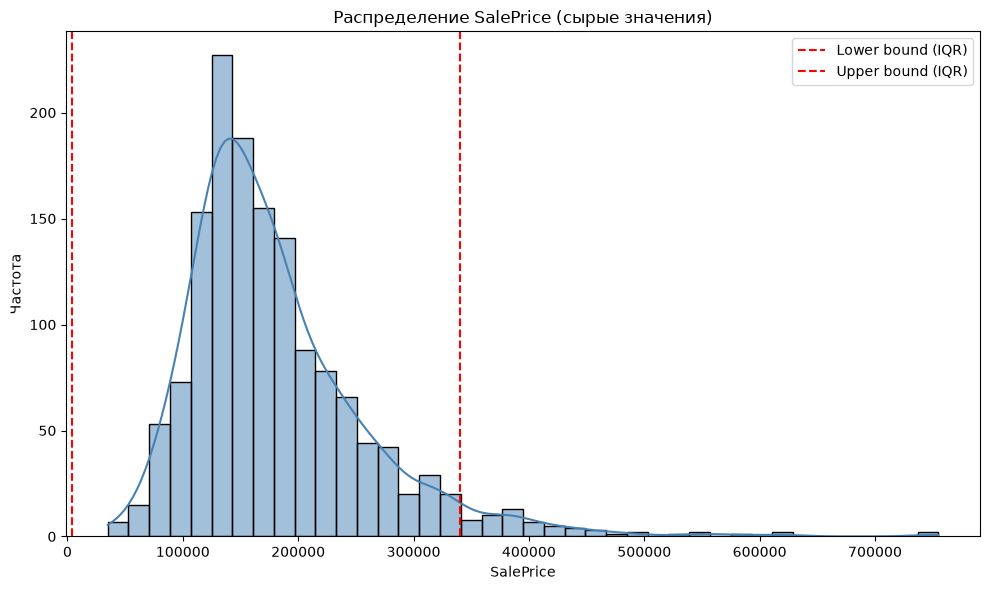

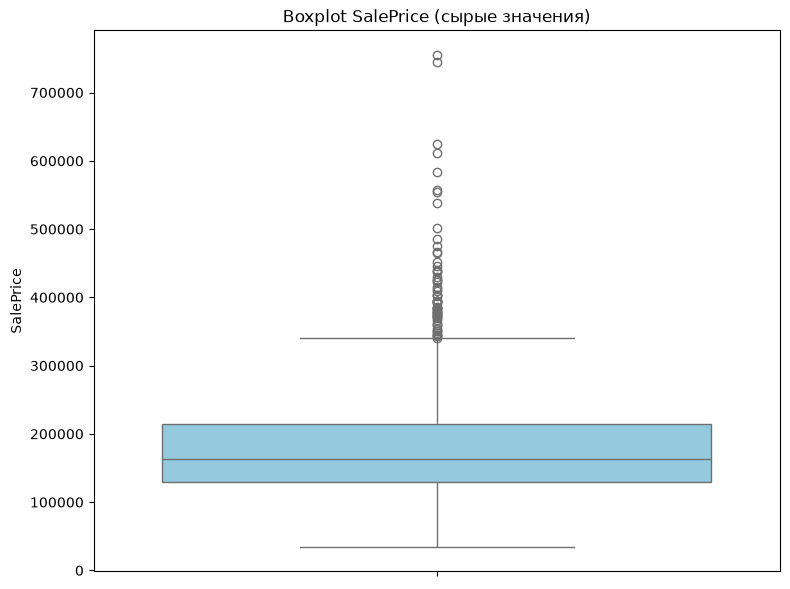

In [10]:
plt.rcParams["figure.figsize"] = (10, 6)

def analyze_target(df, target_col, group_by_col=None, log_transform=True):
   
    y = df[target_col].dropna()

    # --- 1. Базовая статистика ---
    stats = y.describe()
    q1, q3 = np.percentile(y, [25, 75])
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers_mask = (y < lower_bound) | (y > upper_bound)
    n_outliers = outliers_mask.sum()
    pct_outliers = (n_outliers / len(y)) * 100

    print("=== СТАТИСТИКА ЦЕЛЕВОЙ ПЕРЕМЕННОЙ ===")
    print(stats)
    print(f"\nIQR: {iqr:.2f}")
    print(f"Границы выбросов (1.5*IQR): [{lower_bound:.2f}, {upper_bound:.2f}]")
    print(f"Выбросов: {n_outliers} ({pct_outliers:.2f}%)")

    # --- 2. Гистограмма и KDE (сырые значения) ---
    plt.figure(figsize=(10, 6))
    sns.histplot(y, kde=True, bins=40, color="steelblue")
    plt.axvline(lower_bound, color="red", linestyle="--", label="Lower bound (IQR)")
    plt.axvline(upper_bound, color="red", linestyle="--", label="Upper bound (IQR)")
    plt.title(f"Распределение {target_col} (сырые значения)")
    plt.xlabel(target_col)
    plt.ylabel("Частота")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # --- 3. Боксплот (сырые значения) ---
    plt.figure(figsize=(8, 6))
    sns.boxplot(y=y, color="skyblue")
    plt.title(f"Boxplot {target_col} (сырые значения)")
    plt.ylabel(target_col)
    plt.tight_layout()
    plt.show()

   

    # Возвращаем границы выбросов и маски (чтобы можно было удалить/замаскировать в пайплайне)
    return {
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "n_outliers": n_outliers,
        "pct_outliers": pct_outliers,
        "outliers_mask": outliers_mask,
    }

# --- Запуск анализа ---
target_col = 'SalePrice'
group_by_col = 'Neighborhood'  # можно поставить None, если не нужен разрез

analysis_res = analyze_target(train_df, target_col=target_col, group_by_col=group_by_col, log_transform=True)


- Среднее (mean) 180 921 заметно выше медианы (163 000) — это признак правого скоса: есть дорогие дома, которые тянут среднее вверх.
- IQR = 84 025 — довольно широкий разброс цен внутри «типичного» диапазона.
- Границы выбросов (3 937.50, 340 037.50) и 61 выброс (4.18%) — это не «шум», а скорее дорогие дома, которые реально существуют. В Ames такие объекты — не ошибка, а важная часть распределения.
- Максимум 755 000 почти вдвое больше верхней границы IQR — именно эти объекты и дают длинный правый хвост.

Для бустингов (CatBoost/XGB/LightGBM) это значит: если обучать на сырых ценах, модель будет «перетягиваться» на дорогие объекты, а предсказания для типичных домов станут менее точными.

### Анализ распределения числовых  признаков

In [11]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [12]:
# --- Только числовые признаки ---
num_cols = train_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
# Id и целевую переменную убираем из общего анализа
num_cols = [c for c in num_cols if c not in ['Id', 'SalePrice']]


In [13]:
# --- Сводная статистика ---
stats = train_df[num_cols].describe().T
stats['skew'] = train_df[num_cols].skew()          # асимметрия
stats['kurtosis'] = train_df[num_cols].kurtosis()  # эксцесс
stats['nunique'] = train_df[num_cols].nunique()
display(stats.sort_values('skew', ascending=False).head(20))

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,nunique
MiscVal,1460.0,43.489041,496.123024,0.0,0.00,0.0,0.00,15500.0,24.476794,701.003342,21
PoolArea,1460.0,2.758904,40.177307,0.0,0.00,0.0,0.00,738.0,14.828374,223.268499,8
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0,12.207688,203.243271,1073
3SsnPorch,1460.0,3.409589,29.317331,0.0,0.00,0.0,0.00,508.0,10.304342,123.662379,20
LowQualFinSF,1460.0,5.844521,48.623081,0.0,0.00,0.0,0.00,572.0,9.011341,83.234817,24
KitchenAbvGr,1460.0,1.046575,0.220338,0.0,1.00,1.0,1.00,3.0,4.488397,21.532404,4
BsmtFinSF2,1460.0,46.549315,161.319273,0.0,0.00,0.0,0.00,1474.0,4.255261,20.113338,144
ScreenPorch,1460.0,15.060959,55.757415,0.0,0.00,0.0,0.00,480.0,4.122214,18.439068,76
BsmtHalfBath,1460.0,0.057534,0.238753,0.0,0.00,0.0,0.00,2.0,4.103403,16.396642,3
EnclosedPorch,1460.0,21.954110,61.119149,0.0,0.00,0.0,0.00,552.0,3.089872,10.430766,120


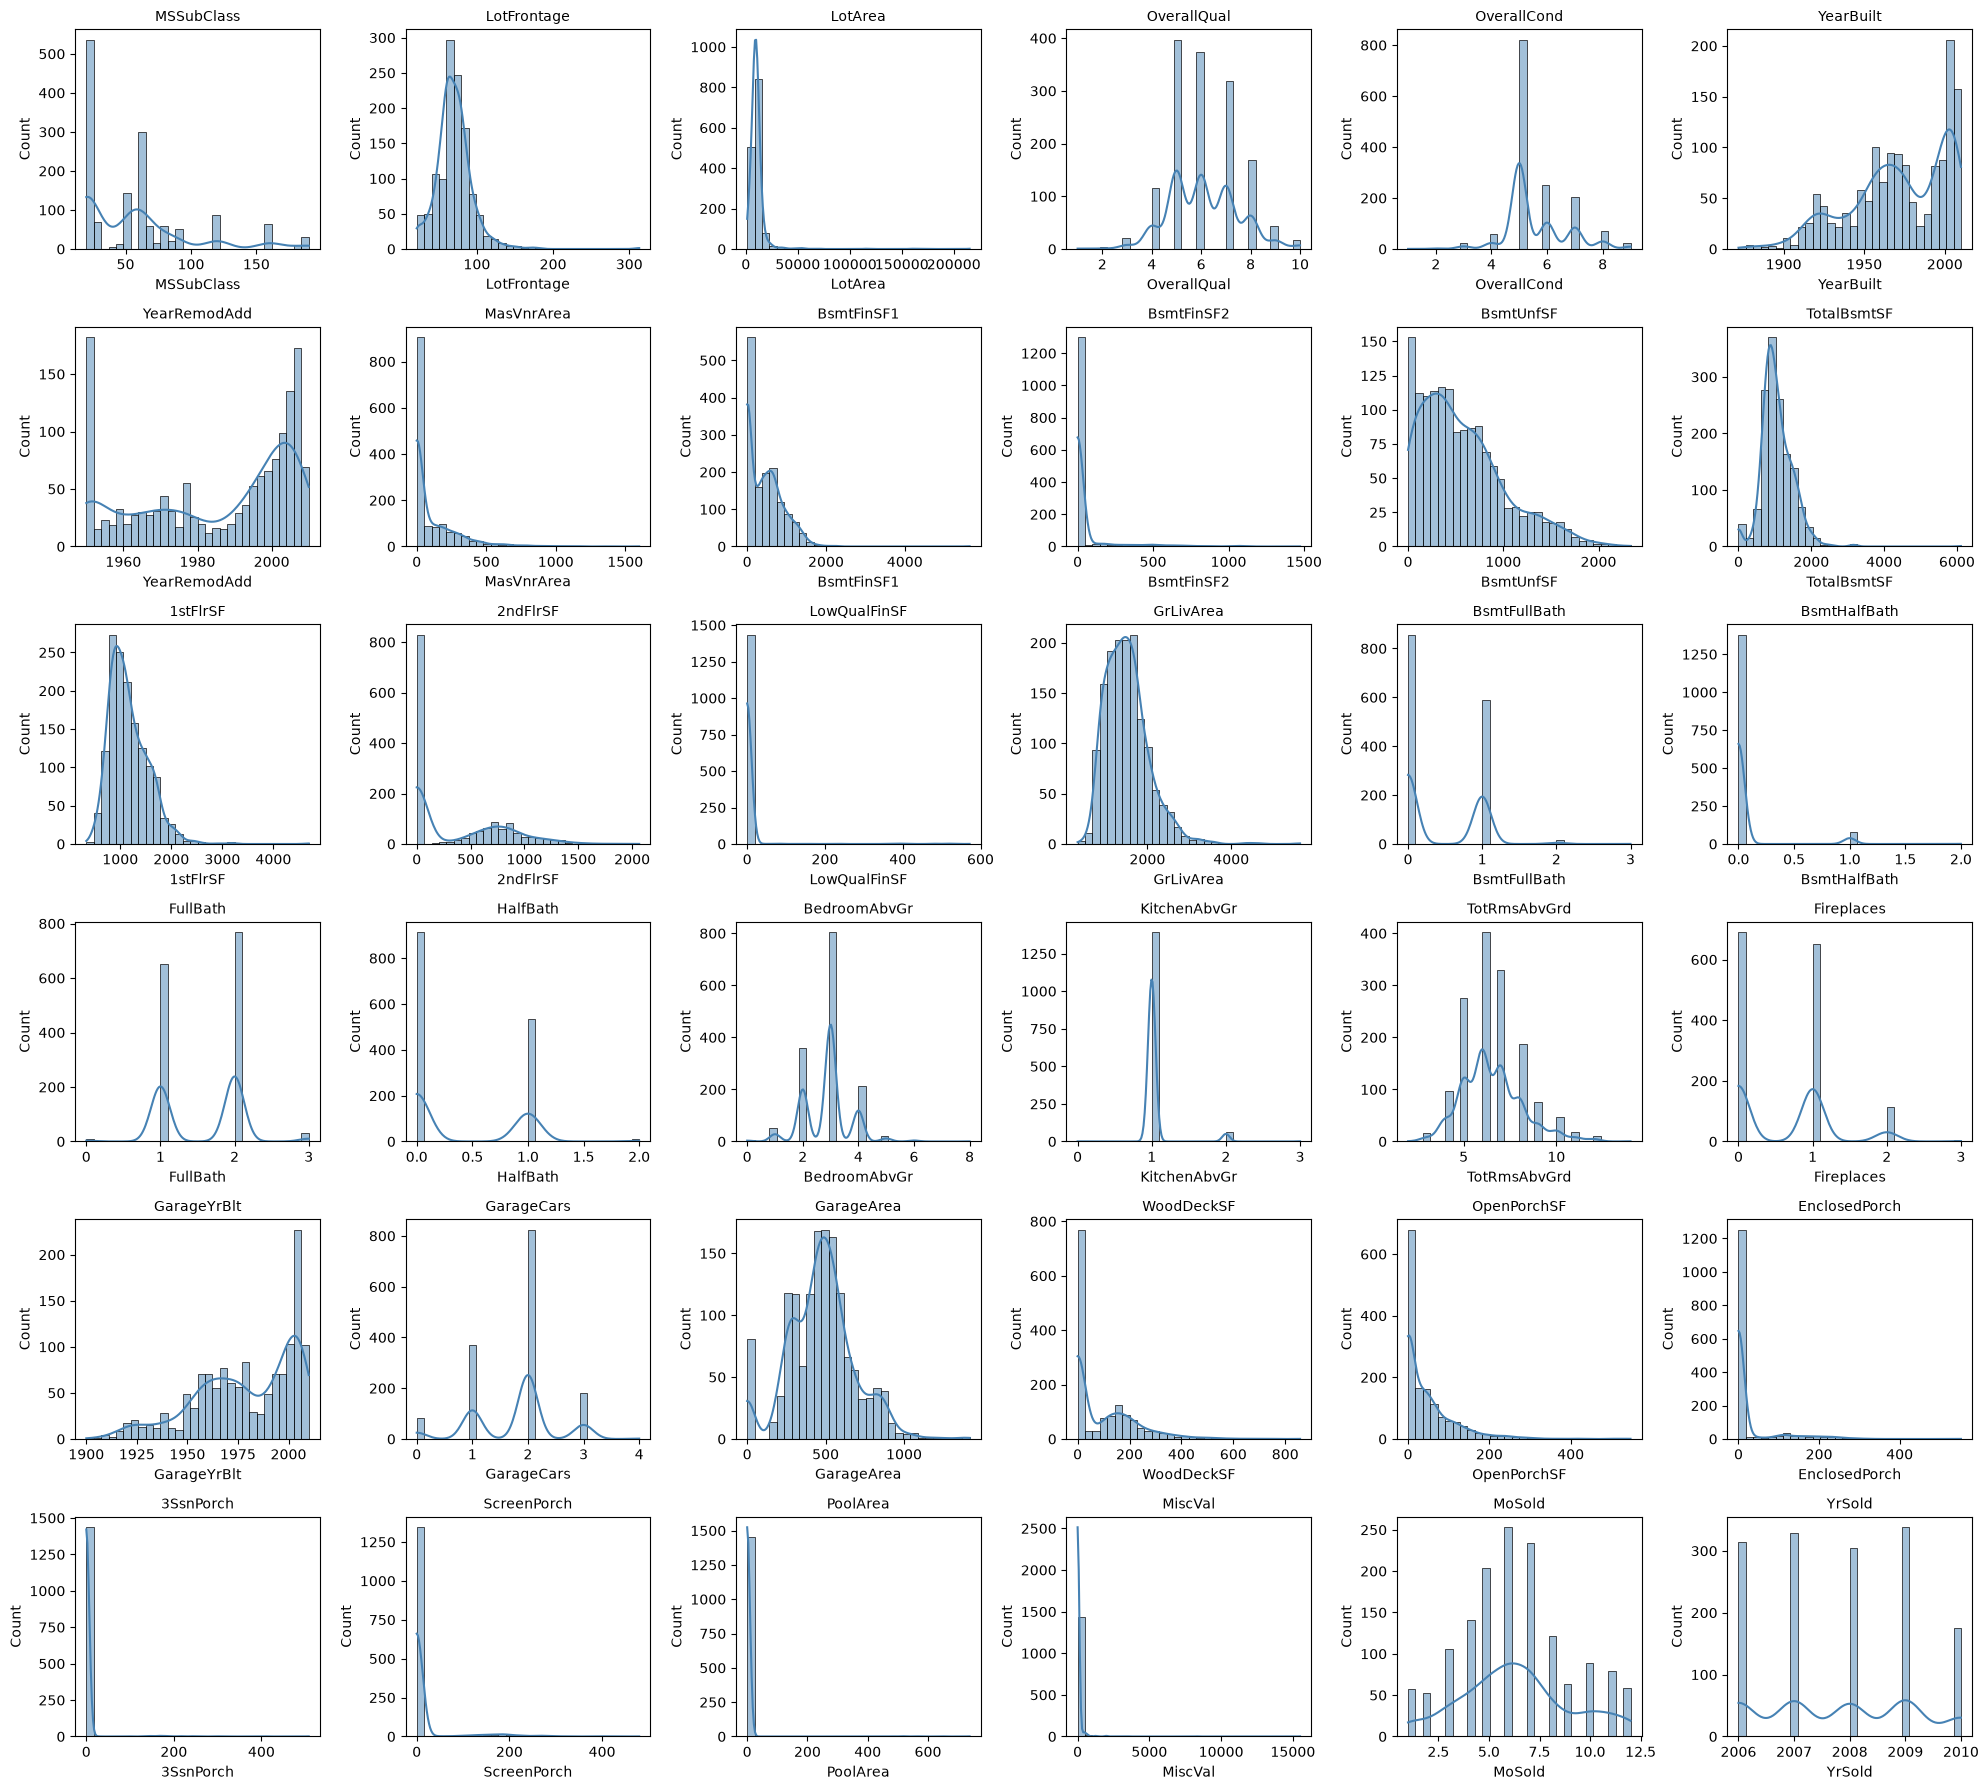

In [14]:
# Рисуем по 6 признаков на сетку
cols = num_cols
n = len(cols)
fig, axes = plt.subplots(nrows=(n + 5) // 6, ncols=6, figsize=(20, 3 * ((n + 5) // 6)))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    sns.histplot(train_df[col], bins=30, kde=True, ax=ax, color='steelblue')
    ax.set_title(col, fontsize=10)

# Скрываем пустые оси
for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig('numeric_distributions.png', dpi=150)
plt.show()


**Экстремально скошенные признаки (skew > 4):**

- Признак	Skew	Комментарий
- MiscVal	24.5	96%+ нулей, полезной информации почти нет
- PoolArea	14.8	бассейн есть всего у ~7 домов из 1460
- LotArea	12.2	вот это интересно — реальный признак, но хвост до 215 000 кв. футов при медиане ~9 500. Тяжёлые выбросы
- 3SsnPorch, LowQualFinSF	9–10	почти вырожденные, 98% нулей
- KitchenAbvGr	4.5	дискретный: медиана 1, почти у всех одна кухня
  
**Умеренно скошенные (1–4):** площади — BsmtFinSF2, MasVnrArea, OpenPorchSF, BsmtFinSF1, WoodDeckSF, TotalBsmtSF, 1stFlrSF, GrLivArea. Классика для площадей жилья — правый хвост из больших домов.

**Почти симметричные:** BsmtUnfSF (0.92) и BsmtHalfBath на фоне остальных выглядят прилично.

**Выбросы в LotArea** — проверить руками: при max 215 245 против 75-го перцентиля 11 601 это, скорее всего, несколько огромных участков, которые уводят модель. Быстрая проверка:

In [15]:
train_df[train_df['LotArea'] > 50000][['Id', 'LotArea', 'SalePrice', 'GrLivArea']]


,Id,LotArea,SalePrice,GrLivArea
53,54,50271,385000,1842
249,250,159000,277000,2144
313,314,215245,375000,2036
335,336,164660,228950,1786
384,385,53107,240000,1953
451,452,70761,280000,1533
457,458,53227,256000,1663
706,707,115149,302000,1824
769,770,53504,538000,3279
1298,1299,63887,160000,5642


In [16]:
p99 = train_df['LotArea'].quantile(0.99)
print(f"99‑й перцентиль (по train): {p99:,.0f}")

# Удаляем выбросы из train
train_clean = train_df[train_df['LotArea'] <= p99].copy()
print(f"Было строк в train: {len(train_df)}, стало: {len(train_clean)}")
print(f"Удалено выбросов: {len(train_df) - len(train_clean)} ({(len(train_df) - len(train_clean)) / len(train_df):.1%})")

99‑й перцентиль (по train): 37,568
Было строк в train: 1460, стало: 1445
Удалено выбросов: 15 (1.0%)


### Анализ категориальных признаков

In [17]:
cat_col = train_df.select_dtypes(include=['object']).columns.tolist()

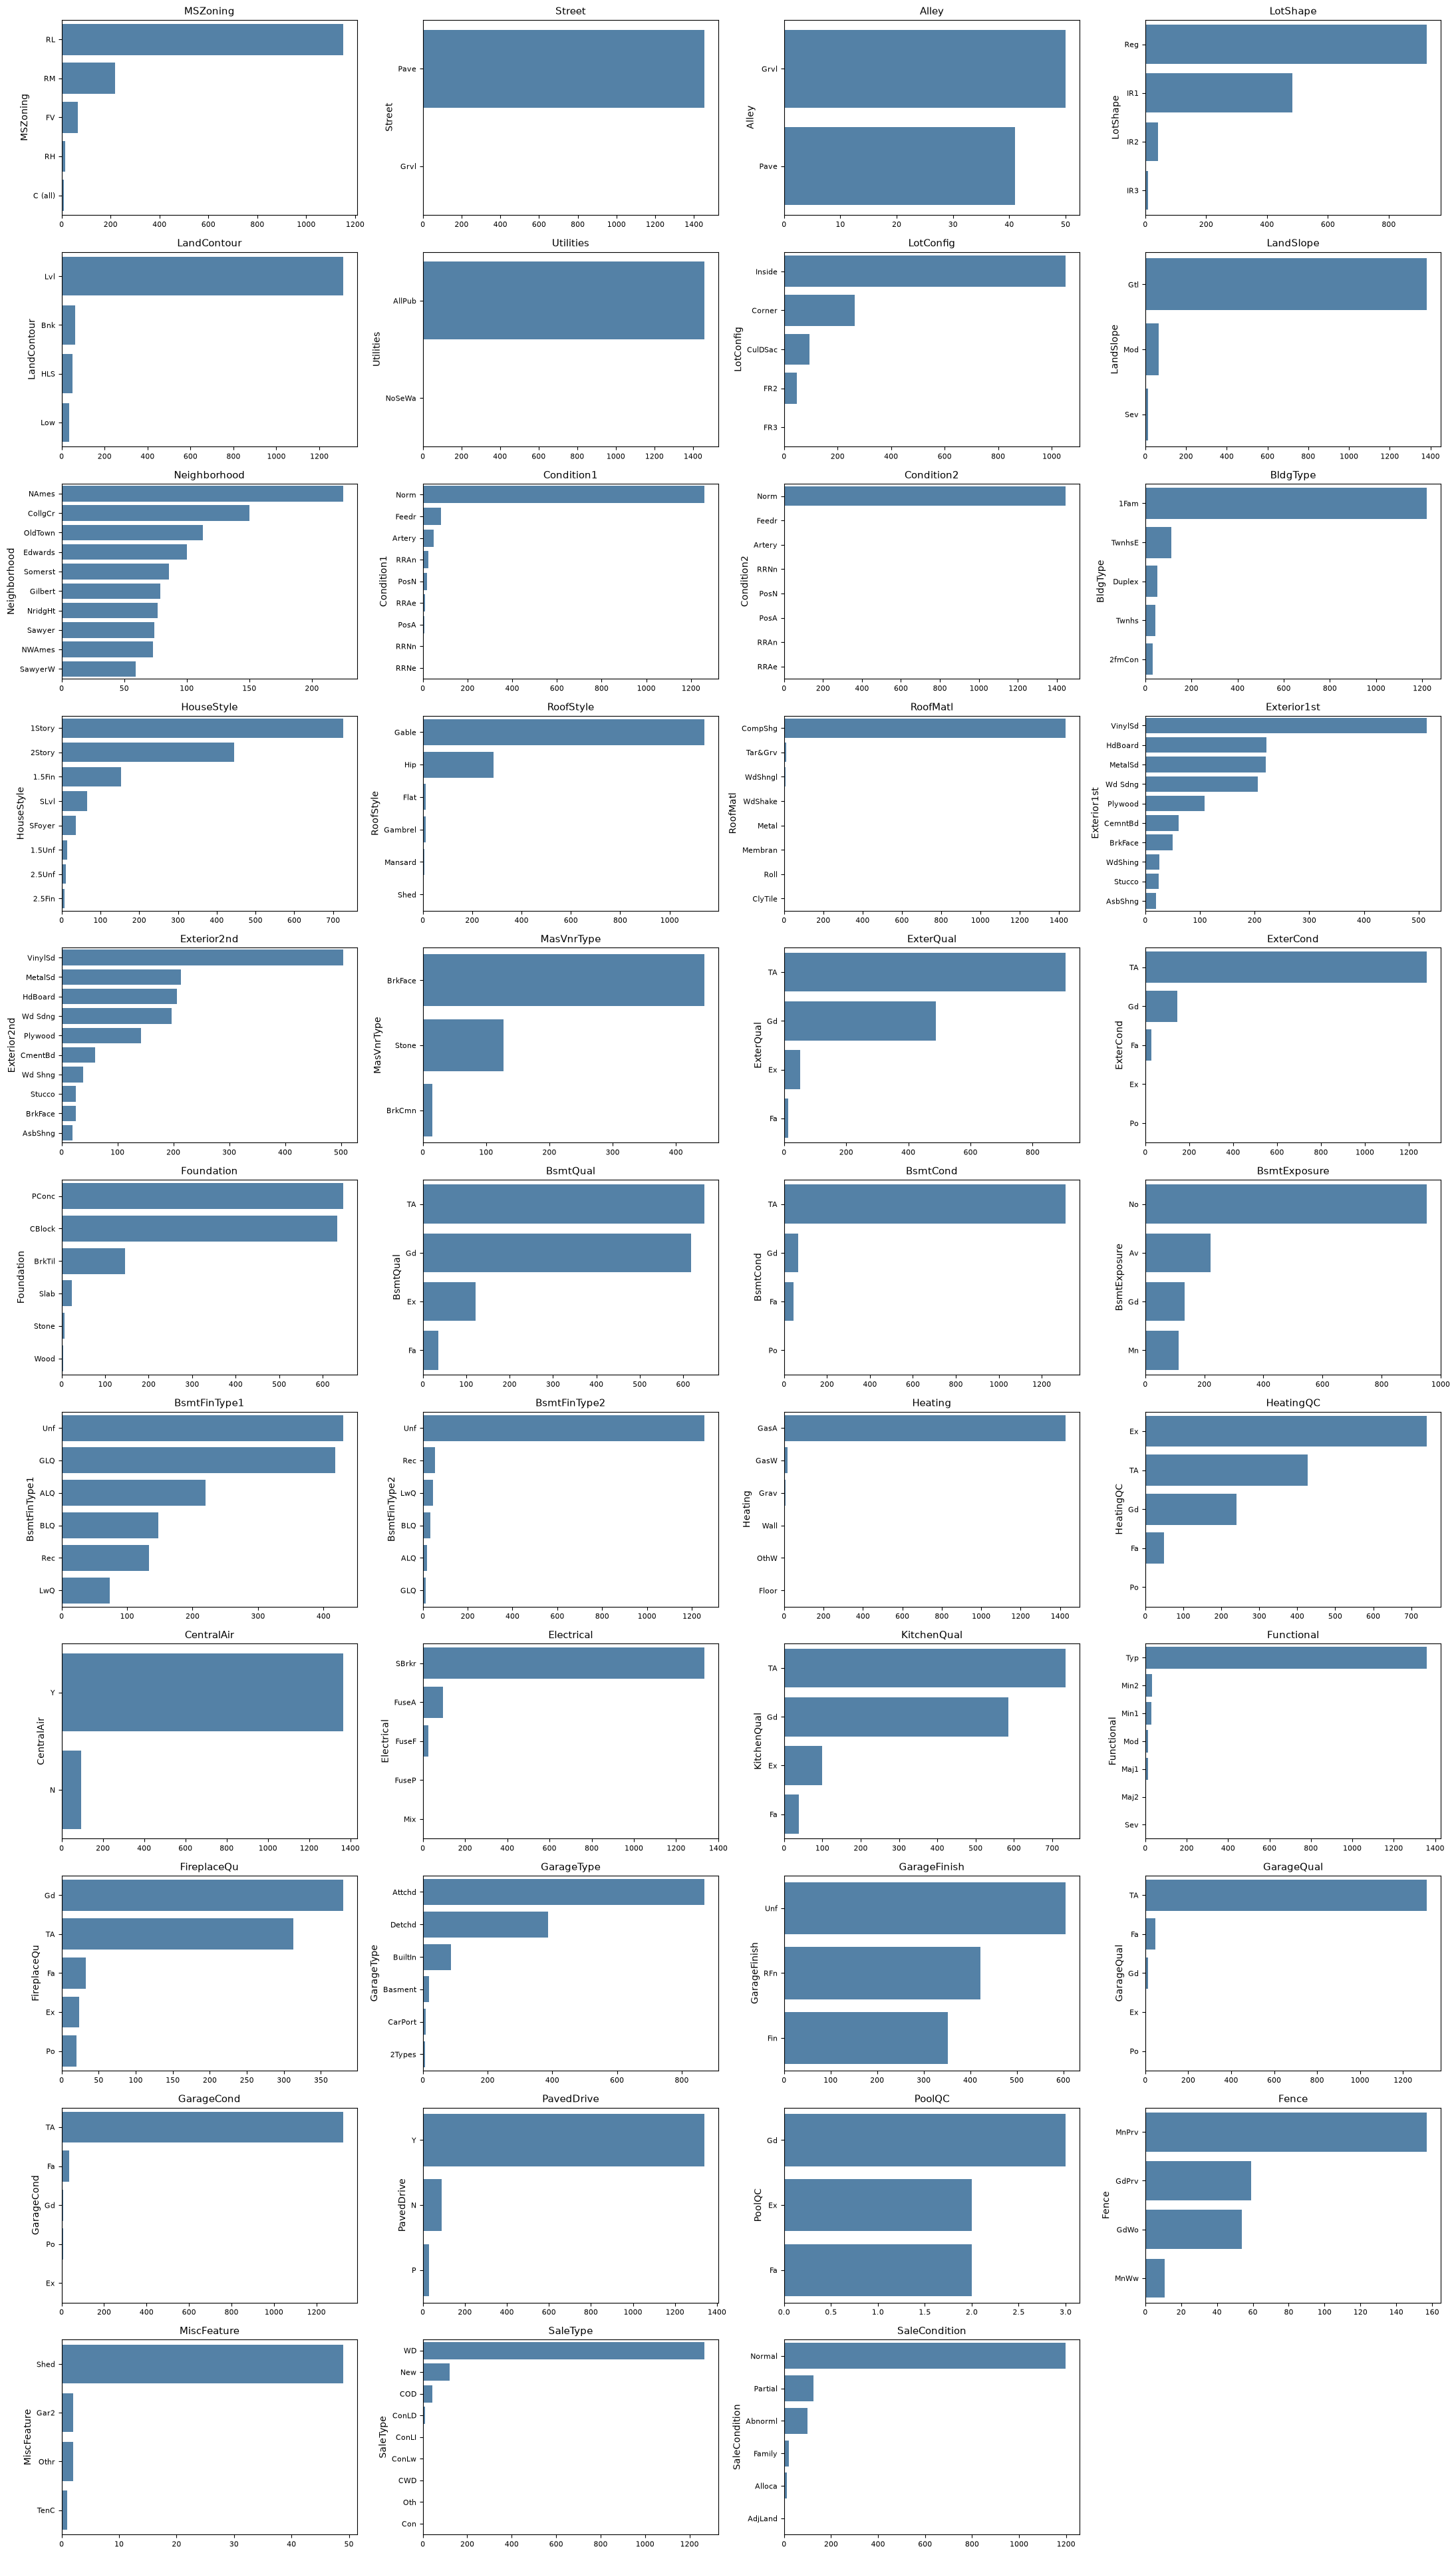

In [18]:
# --- 1. Счётчики категорий (barplot) ---
n = len(cat_col)
nrows = (n + 3) // 4
fig, axes = plt.subplots(nrows, 4, figsize=(22, 3.5 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, cat_col):
    counts = train_df[col].value_counts().head(10)  # топ-10 категорий
    sns.barplot(x=counts.values, y=counts.index, ax=ax, color='steelblue')
    ax.set_title(col, fontsize=11)
    ax.tick_params(labelsize=8)

for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig('categorical_counts.png', dpi=150)
plt.show()

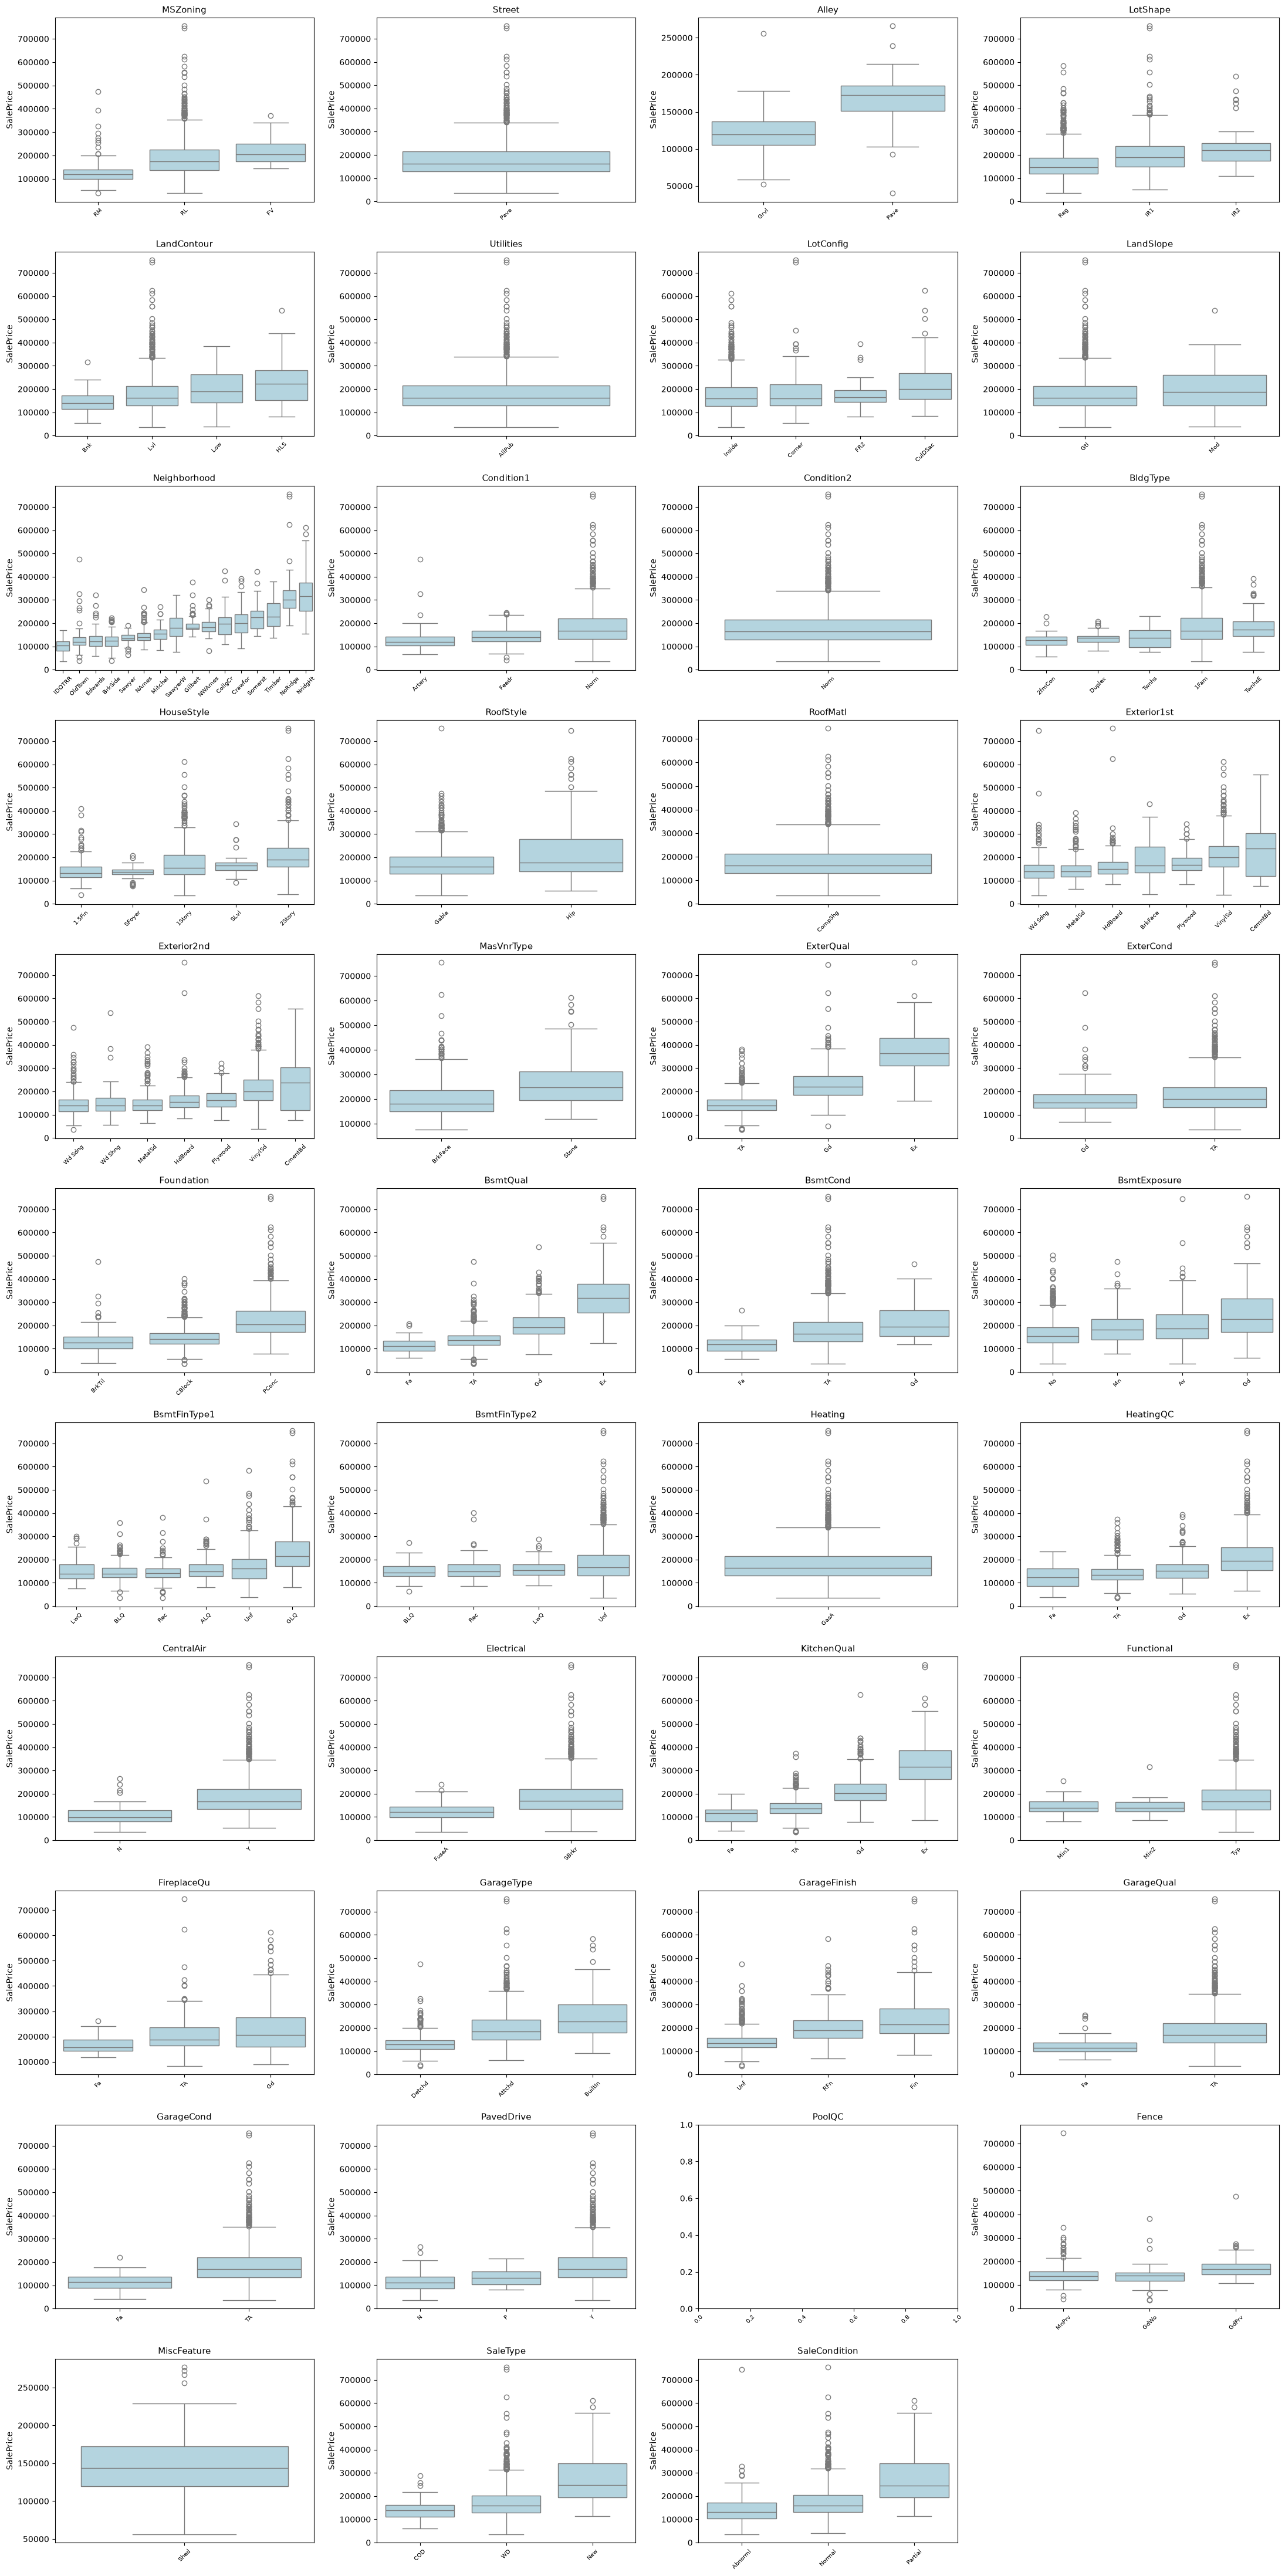

In [19]:
# --- 2. Распределение цены по категориям (boxplot) ---
nrows = (n + 3) // 4
fig, axes = plt.subplots(nrows, 4, figsize=(22, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, cat_col):
    # берём только категории с >= 30 объектами, иначе боксплот шумит
    vc = train_df[col].value_counts()
    valid = train_df[train_df[col].isin(vc[vc >= 30].index)]
    sns.boxplot(x=col, y='SalePrice', data=valid, ax=ax, color='lightblue',
                order=valid.groupby(col)['SalePrice'].median().sort_values().index)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel('')
    ax.tick_params(axis='x', labelsize=7, rotation=45)

for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig('categorical_price_boxplots.png', dpi=150)
plt.show()


In [20]:
dominance = (train_df[cat_col]
             .apply(lambda s: s.value_counts(normalize=True).iloc[0])
             .sort_values(ascending=False))
print(dominance[dominance > 0.95])


Utilities     0.999315
Street        0.995890
Condition2    0.989726
RoofMatl      0.982192
Heating       0.978082
GarageCond    0.961566
GarageQual    0.950689
dtype: float64


- Utilities — 99.9% объектов имеют AllPub (все коммуникации), в train ровно 1 дом с NoSeWa. 
- Street, Condition2, RoofMatl, Heating — у 97–99% домов одно и то же значение (Pave, Norm, CompShg, GasA). Модель ничего из них не выжмет.
- GarageCond, GarageQual — здесь нюанс: доминирует не просто TA, а TA при наличии гаража. Часть «пропусков» — это дома без гаража. 

## Моделирование

In [21]:
X = train_df.drop(columns=['SalePrice'])
y = train_df['SalePrice']

# Заполняем NaN в категориальных колонках строкой 'None'
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

X[cat_cols] = X[cat_cols].fillna('None')
# Разделение на train/val (для быстрой проверки)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Определяем, какие колонки — категориальные
cat_features = X.select_dtypes(include=['object']).columns.tolist()

model = CatBoostRegressor(
    iterations=1000,
    depth=6,
    learning_rate=0.03,
    loss_function='RMSE',
    verbose=100,          # лог каждые 100 итераций
    early_stopping_rounds=50,  # остановка, если не улучшается
    random_seed=42,
    cat_features=cat_features  # передаём список категориальных колонок
)

model.fit(X_train, y_train, eval_set=(X_val, y_val))

# Оценка на валидации
y_pred = model.predict(X_val)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
print(f"RMSE на валидации: {rmse:,.2f}")

0:	learn: 75766.2338140	test: 86094.6716812	best: 86094.6716812 (0)	total: 222ms	remaining: 3m 41s
100:	learn: 26382.0065858	test: 35384.4627580	best: 35384.4627580 (100)	total: 3.47s	remaining: 30.9s
200:	learn: 19892.5147574	test: 30586.5151824	best: 30570.3440988 (199)	total: 6.25s	remaining: 24.8s
300:	learn: 16874.8166993	test: 28715.4678543	best: 28715.4678543 (300)	total: 9.04s	remaining: 21s
400:	learn: 15215.9850741	test: 28091.5859818	best: 28091.5859818 (400)	total: 11.8s	remaining: 17.7s
500:	learn: 14088.8577818	test: 27858.3165400	best: 27858.3165400 (500)	total: 14.6s	remaining: 14.6s
600:	learn: 13008.8723225	test: 27754.9931487	best: 27750.9327003 (599)	total: 17.5s	remaining: 11.6s
700:	learn: 12081.4624180	test: 27681.5644413	best: 27655.1569398 (660)	total: 20.4s	remaining: 8.7s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 27655.15694
bestIteration = 660

Shrink model to first 661 iterations.
RMSE на валидации: 27,655.16


In [22]:
y_log = np.log1p(train_df['SalePrice'])

X_train, X_val, y_train, y_val = train_test_split(X, y_log, test_size=0.2, random_state=42)

model.fit(X_train, y_train, eval_set=(X_val, y_val))

y_pred_log = model.predict(X_val)
rmse_log = np.sqrt(mean_squared_error(y_val, y_pred_log))
print(f"RMSE (log-шкала, как на Kaggle): {rmse_log:.4f}")


0:	learn: 0.3824618	test: 0.4247666	best: 0.4247666 (0)	total: 24.9ms	remaining: 24.9s
100:	learn: 0.1373268	test: 0.1682386	best: 0.1682386 (100)	total: 2.75s	remaining: 24.4s
200:	learn: 0.1060541	test: 0.1423839	best: 0.1423839 (200)	total: 5.47s	remaining: 21.7s
300:	learn: 0.0946623	test: 0.1370408	best: 0.1370287 (299)	total: 8.21s	remaining: 19.1s
400:	learn: 0.0873546	test: 0.1344147	best: 0.1344147 (400)	total: 11s	remaining: 16.4s
500:	learn: 0.0818929	test: 0.1335516	best: 0.1334886 (497)	total: 14s	remaining: 13.9s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.1334207783
bestIteration = 522

Shrink model to first 523 iterations.
RMSE (log-шкала, как на Kaggle): 0.1334


In [23]:

def objective(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 400, 1200),  # меньше деревьев
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 7),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 10.0, log=True),
        'loss_function': 'RMSE',
        'random_seed': 42,
        'verbose': 0,
        'thread_count': -1
    }

    # Один holdout вместо CV — в 3 раза быстрее за попытку
    X_tr, X_val, y_tr, y_val = train_test_split(X, y_log, test_size=0.2, random_state=42)

    model = CatBoostRegressor(**params, cat_features=cat_features,
                              early_stopping_rounds=50)
    model.fit(X_tr, y_tr, eval_set=(X_val, y_val), verbose=0)
    return np.sqrt(mean_squared_error(y_val, model.predict(X_val)))

study = optuna.create_study(direction='minimize',
                            sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30, show_progress_bar=True)
print("Лучшие параметры:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")
print(f"Лучший CV RMSE (log): {study.best_value:.4f}")

[I 2026-11-16 17:16:11,506] A new study created in memory with name: no-name-eb3d34b9-3f51-4c5c-b55a-95e787518850


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-16 17:16:22,391] Trial 0 finished with value: 0.12999052137386008 and parameters: {'iterations': 700, 'learning_rate': 0.09237421878009823, 'depth': 6, 'l2_leaf_reg': 3.968793330444372}. Best is trial 0 with value: 0.12999052137386008.
[I 2026-11-16 17:16:30,718] Trial 1 finished with value: 0.1386137248821376 and parameters: {'iterations': 524, 'learning_rate': 0.025707833957860277, 'depth': 4, 'l2_leaf_reg': 7.348118405270449}. Best is trial 0 with value: 0.12999052137386008.
[I 2026-11-16 17:16:41,711] Trial 2 finished with value: 0.13156605139791697 and parameters: {'iterations': 881, 'learning_rate': 0.06251028636335225, 'depth': 4, 'l2_leaf_reg': 9.330606024425668}. Best is trial 0 with value: 0.12999052137386008.
[I 2026-11-16 17:16:55,230] Trial 3 finished with value: 0.1321931903023718 and parameters: {'iterations': 1066, 'learning_rate': 0.02814807274769496, 'depth': 4, 'l2_leaf_reg': 1.5254729458052607}. Best is trial 0 with value: 0.12999052137386008.
[I 2026-11-

In [24]:
final_params = {
    'iterations': 800,                 
    'learning_rate': 0.050034001497179806,
    'depth': 5,
    'l2_leaf_reg': 2.0810678987912943,
    'loss_function': 'RMSE',
    'random_seed': 42,
    'verbose': 100,
    'thread_count': -1
}

X_train, X_val, y_train, y_val = train_test_split(X, y_log, test_size=0.2, random_state=42)

final_model = CatBoostRegressor(**final_params, cat_features=cat_features)
final_model.fit(X_train, y_train, eval_set=(X_val, y_val))

print(f"RMSE на валидации: {np.sqrt(mean_squared_error(y_val, final_model.predict(X_val))):.4f}")


0:	learn: 0.3778210	test: 0.4197676	best: 0.4197676 (0)	total: 21.6ms	remaining: 17.2s
100:	learn: 0.1170597	test: 0.1461918	best: 0.1461918 (100)	total: 2.26s	remaining: 15.6s
200:	learn: 0.0969062	test: 0.1349458	best: 0.1349247 (198)	total: 4.44s	remaining: 13.2s
300:	learn: 0.0851253	test: 0.1322790	best: 0.1322137 (294)	total: 6.68s	remaining: 11.1s
400:	learn: 0.0777365	test: 0.1314670	best: 0.1314596 (397)	total: 8.95s	remaining: 8.9s
500:	learn: 0.0718326	test: 0.1306489	best: 0.1306489 (500)	total: 11.2s	remaining: 6.68s
600:	learn: 0.0667145	test: 0.1301645	best: 0.1301645 (600)	total: 13.4s	remaining: 4.43s
700:	learn: 0.0621487	test: 0.1296673	best: 0.1295456 (671)	total: 15.6s	remaining: 2.2s
799:	learn: 0.0577353	test: 0.1297033	best: 0.1295456 (671)	total: 17.8s	remaining: 0us

bestTest = 0.1295456445
bestIteration = 671

Shrink model to first 672 iterations.
RMSE на валидации: 0.1295


In [25]:
# 1. Переобучаем на всём train с найденной лучшей итерацией (без eval_set)
final_model_full = CatBoostRegressor(
    **final_params,     
    cat_features=cat_features
)
final_model_full.fit(X, y_log)


0:	learn: 0.3861314	total: 20.3ms	remaining: 16.2s
100:	learn: 0.1176766	total: 2.27s	remaining: 15.7s
200:	learn: 0.0994096	total: 4.49s	remaining: 13.4s
300:	learn: 0.0918294	total: 6.78s	remaining: 11.2s
400:	learn: 0.0852020	total: 9.06s	remaining: 9.01s
500:	learn: 0.0779595	total: 11.3s	remaining: 6.73s
600:	learn: 0.0725253	total: 13.5s	remaining: 4.47s
700:	learn: 0.0670740	total: 15.7s	remaining: 2.22s
799:	learn: 0.0632507	total: 17.9s	remaining: 0us


CatBoostRegressor(cat_features=['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition'], depth=5, iterations=800, l2_leaf_reg=2.0810678987912943, learning_rate=0.050034001497179806, loss_function='RMSE', random_seed=42, verbose=100)

In [26]:
# 2. Подготовка тестовых данных (важно: те же колонки и заполнение категорий)
test_df[cat_cols] = test_df[cat_cols].fillna('None')

# 3. Предсказание и возврат к исходной шкале цен
y_pred_log = final_model_full.predict(test_df[X.columns])
y_pred = np.expm1(y_pred_log)  

# 4. Формирование файла для сабмита
submission = pd.DataFrame({
    'Id': test_df['Id'],
    'SalePrice': y_pred
})
submission.to_csv('submission_catboost.csv', index=False)
print("Файл submission_catboost.csv сохранён.")

Файл submission_catboost.csv сохранён.
